<a href="https://colab.research.google.com/github/adityarasal8-gif/Optimization-Techniques-Practicals/blob/main/OT_MSPA_4_(Mini_Project).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

MODE=fast; representative days=36; hourly optimization steps=864
Core optimizations completed in 0.9 seconds.

=== MAIN RESULTS ===


,Case,PV (kW),Battery (kWh),Battery inverter (kW),Capex (Rs lakh),Annual bill (Rs lakh),Savings (Rs lakh/yr),Payback (years),NPV 25y (Rs lakh),CO2 (tonnes/yr)
0,Grid only (today),0.0,0.0,0.0,0.00,54.01,0.00,inf,0.00,566.4
1,Solar only,200.0,0.0,0.0,90.00,35.85,18.16,5.0,74.87,367.3
2,Solar + Battery (optimal),200.0,11.8,10.1,93.16,35.35,18.66,5.0,74.92,366.5



=== STOCHASTIC PLANNING ===
Normal-year design: PV 200.0 kW, battery 11.8 kWh
Weather-robust design: PV 200.0 kW, battery 10.1 kWh
Expected annual cost using normal-year design: Rs 4,687,350
Expected annual cost using stochastic design: Rs 4,687,334
Value of stochastic solution: Rs 16/year

=== COST VS CO2 ===


,CO2 (t/yr),Annualized cost (Rs lakh),PV (kW),Battery (kWh)
0,366.52,45.73,200.0,11.79
1,365.18,46.10,200.0,47.71
2,363.84,46.91,200.0,82.20
3,362.49,47.84,200.0,105.70
4,361.15,49.96,200.0,172.25
5,359.81,54.31,200.0,293.42



=== SENSITIVITY TO BATTERY PRICE ===


...


=== SENSITIVITY TO ROOF SIZE ===


,Roof limit (kW),Optimal PV (kW),Battery (kWh),Annualized cost (Rs lakh)
0,100,100.00,4.35,49.50
1,200,200.00,11.79,45.73
2,300,300.00,27.74,43.66
3,500,429.32,34.60,42.81
4,800,429.32,34.60,42.81



VALIDATION PASSED: energy balance, battery dynamics, SOC, power, export, roof, peaks and CO2 checks.

=== ELECTRICITY BILL (Rs lakh/year) ===


,Grid only,Solar only,Solar + battery
Energy charges,47.523,30.523,30.373
Demand charges,6.490,5.644,5.179
Export credit,-0.000,-0.318,-0.278
Battery wear,0.000,0.000,0.074
TOTAL BILL,54.013,35.849,35.348


Annual bill: Rs 54.01 lakh -> Rs 35.35 lakh
Annual bill saving: Rs 18.66 lakh (34.6%).
Grid electricity: 690.8 -> 447.0 MWh/year
CO2 emissions: 566.4 -> 366.5 tonnes/year


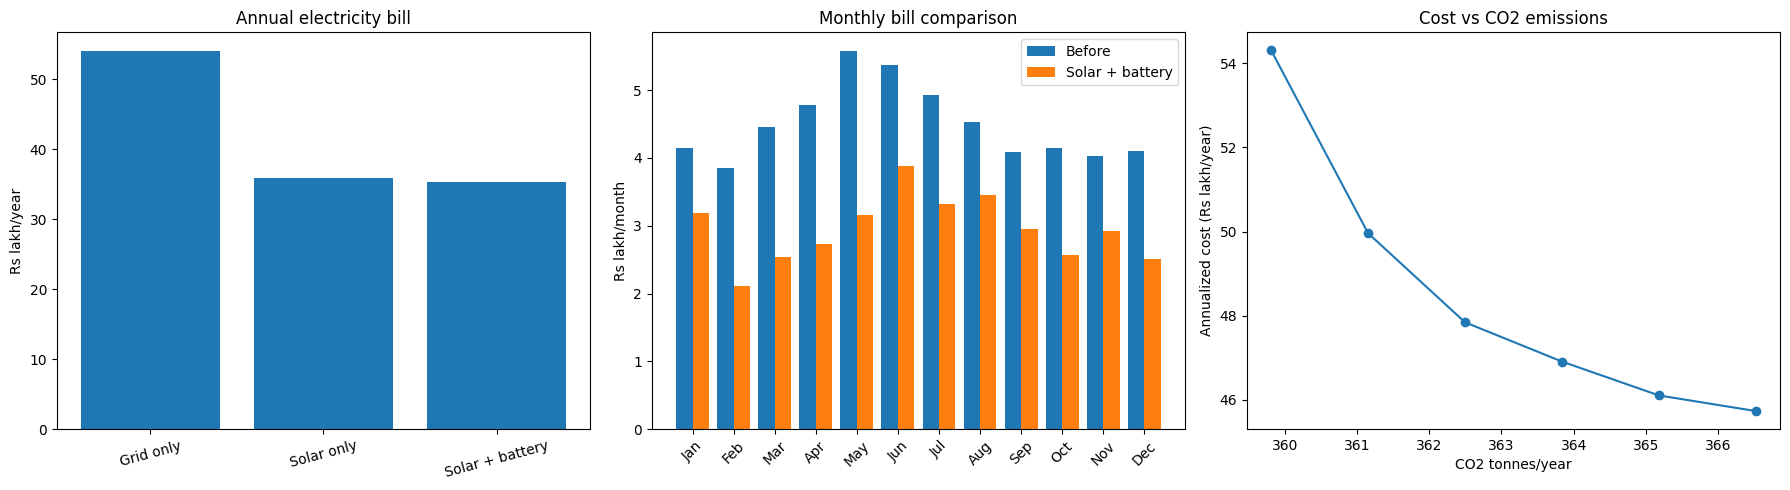

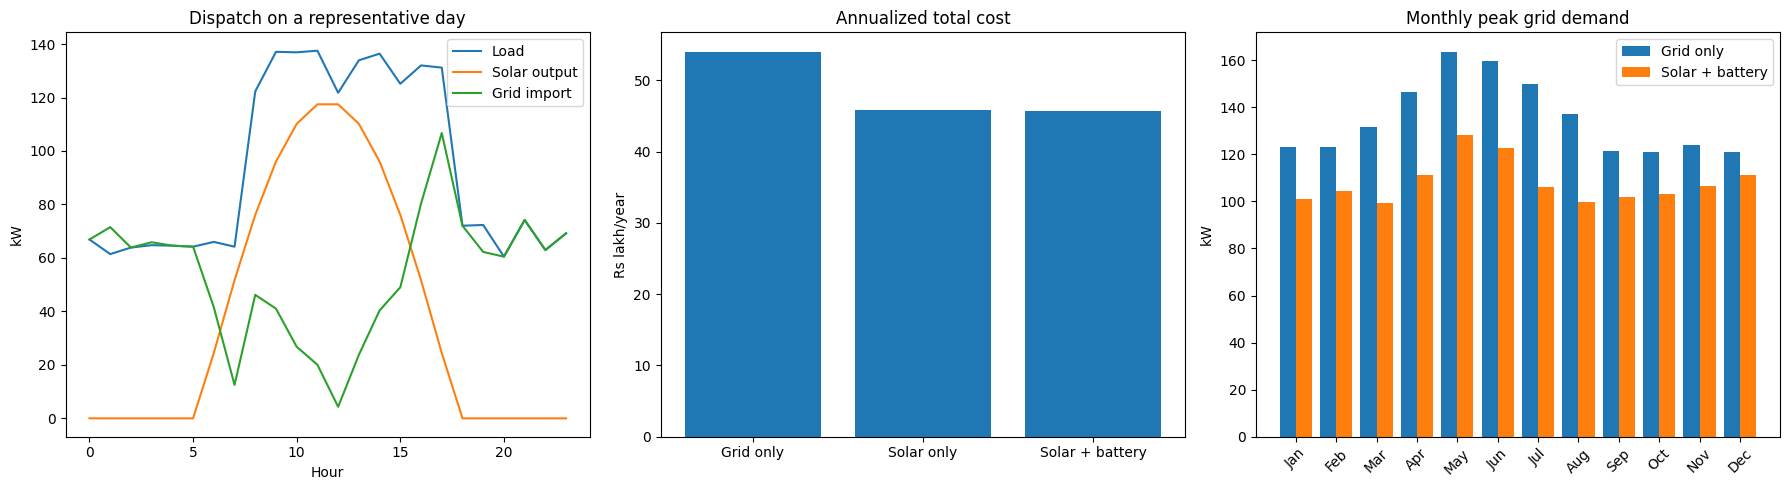


Saved files: main_results.csv, bill_before_after.png, optimizer_results.png
Total runtime: 26.9 seconds


In [1]:
# Solar + Battery Sizing and Electricity-Bill Optimizer
# Google Colab-ready. Uses synthetic hourly data by default.
# For real data, upload load.csv (column: kW) and cf.csv (column: cf), each with 8760 rows.

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import linprog
from scipy.sparse import coo_matrix

# -------------------- 1. SETTINGS --------------------
MODE = "fast"                 # "fast" = representative days; "full" = all 8760 hours
USE_REAL_DATA = False         # True to use load.csv and cf.csv
RUN_FULL_CHECK = False        # True runs an additional, potentially slower full-year optimization
RUN_SENSITIVITY = True
RANDOM_SEED = 42

P = {
    "pv_cost": 45000.0,       # Rs per kW installed
    "bat_cost_kwh": 20000.0,  # Rs per kWh battery capacity
    "bat_cost_kw": 8000.0,    # Rs per kW battery inverter
    "pv_life": 25,
    "bat_life": 12,
    "disc": 0.10,
    "eta": 0.95,              # one-way efficiency
    "soc_min": 0.10,          # minimum state of charge fraction
    "deg_cost": 2.0,          # Rs per kWh discharged
    "feedin": 3.0,            # Rs per kWh exported
    "demand_charge": 400.0,   # Rs per kW per month
    "roof_kw_max": 200.0,
    "ef": 0.82,               # kg CO2 per kWh grid electricity
    "cmax": 1.0,              # max battery kW per kWh capacity
}

def tariff_for_hour(h):
    if h >= 22 or h < 6:
        return 5.5
    if 18 <= h < 22:
        return 9.0
    return 7.0

PERIODS = [
    ("Off-peak (22-6h)", 5.5),
    ("Normal (6-18h)", 7.0),
    ("Peak (18-22h)", 9.0),
]

# -------------------- 2. HOURLY DATA --------------------
T_FULL = 8760
idx = pd.date_range("2023-01-01", periods=T_FULL, freq="h")
hour = idx.hour.to_numpy()
month = idx.month.to_numpy() - 1
doy = idx.dayofyear.to_numpy()
weekend = idx.dayofweek.to_numpy() >= 5
rng = np.random.default_rng(RANDOM_SEED)

def synth_load():
    occupancy = np.where((hour >= 8) & (hour < 18), 70.0, 15.0)
    occupancy = np.where(weekend, occupancy * 0.4, occupancy)
    season = 1 + 0.35 * np.exp(-((month - 4.5) ** 2) / 4)
    noise = np.clip(1 + 0.05 * rng.standard_normal(T_FULL), 0.8, None)
    return (40.0 + occupancy) * season * noise

def synth_cf():
    decl = 23.45 * np.sin(np.radians(360 * (284 + doy) / 365))
    lat = 21.1
    ha = 15 * (hour + 0.5 - 12)
    cosz = (
        np.sin(np.radians(lat)) * np.sin(np.radians(decl))
        + np.cos(np.radians(lat)) * np.cos(np.radians(decl))
        * np.cos(np.radians(ha))
    )
    daily_cloud = np.clip(rng.beta(5, 1.5, 365), 0.2, 1)
    monsoon = np.where((month >= 5) & (month <= 8), 0.55, 1.0)
    return np.clip(np.clip(cosz, 0, None) * 0.80 * daily_cloud[doy - 1] * monsoon, 0, 1)

if USE_REAL_DATA:
    load_full = pd.read_csv("load.csv")["kW"].to_numpy(dtype=float)
    cf_full = pd.read_csv("cf.csv")["cf"].to_numpy(dtype=float)
    if len(load_full) != T_FULL or len(cf_full) != T_FULL:
        raise ValueError("load.csv and cf.csv must each contain exactly 8760 hourly rows.")
    if not np.isfinite(load_full).all() or not np.isfinite(cf_full).all():
        raise ValueError("Input data contains NaN or infinite values.")
    if (load_full < 0).any():
        raise ValueError("Load values must be non-negative.")
    if ((cf_full < 0) | (cf_full > 1)).any():
        raise ValueError("Capacity factor values must be between 0 and 1.")
else:
    load_full = synth_load()
    cf_full = synth_cf()

tariff_full = np.array([tariff_for_hour(h) for h in hour], dtype=float)

# -------------------- 3. REPRESENTATIVE DAYS --------------------
def build_days(mode):
    if mode == "full":
        return [(d, 1.0) for d in range(1, 366)]
    if mode != "fast":
        raise ValueError("MODE must be 'fast' or 'full'.")

    result = []
    for m in range(12):
        days = sorted(np.unique(doy[month == m]).tolist())
        day_energy = {
            d: load_full[(d - 1) * 24:d * 24].sum()
            for d in days
        }
        peak_day = max(days, key=lambda d: day_energy[d])
        weekdays = [d for d in days if not weekend[(d - 1) * 24]]
        weekends = [d for d in days if weekend[(d - 1) * 24]]

        # Represent the highest-load day separately; represent the remaining
        # weekdays/weekends with their median-energy day and appropriate weight.
        result.append((peak_day, 1.0))
        remaining_weekdays = [d for d in weekdays if d != peak_day]
        remaining_weekends = [d for d in weekends if d != peak_day]

        if remaining_weekdays:
            med_wd = sorted(remaining_weekdays, key=lambda d: day_energy[d])[len(remaining_weekdays) // 2]
            result.append((med_wd, float(len(remaining_weekdays))))
        if remaining_weekends:
            med_we = sorted(remaining_weekends, key=lambda d: day_energy[d])[len(remaining_weekends) // 2]
            result.append((med_we, float(len(remaining_weekends))))
    return result

SCENARIOS = [
    ("sunny", 1.05, 1.00, 0.30),
    ("normal", 1.00, 1.00, 0.50),
    ("cloudy", 0.75, 1.05, 0.20),
]

def make_scenarios(cf, load, definitions):
    total_probability = sum(x[3] for x in definitions)
    return [
        {
            "name": name,
            "cf": np.clip(cf * solar_factor, 0, 1),
            "L": load * load_factor,
            "w": probability / total_probability,
        }
        for name, solar_factor, load_factor, probability in definitions
    ]

def set_axis(mode):
    global DAYS, sel, tw, N, load, cf, tariff, mon, hsel, prev
    DAYS = build_days(mode)
    sel = np.concatenate([np.arange((d - 1) * 24, d * 24) for d, _ in DAYS])
    tw = np.concatenate([np.full(24, weight) for _, weight in DAYS])
    N = len(sel)
    load = load_full[sel]
    cf = cf_full[sel]
    tariff = tariff_full[sel]
    mon = month[sel]
    hsel = hour[sel]
    # Previous hour within the same representative day (cyclic daily operation).
    prev = np.array([(i // 24) * 24 + ((i % 24) - 1) % 24 for i in range(N)])
    if abs(tw.sum() - T_FULL) > 1e-6:
        raise AssertionError(f"Hourly weights sum to {tw.sum()}, not 8760 hours.")

def scenario_set():
    return make_scenarios(cf, load, [("normal", 1.0, 1.0, 1.0)])

set_axis(MODE)
NORMAL = scenario_set()

# -------------------- 4. FINANCIAL HELPERS --------------------
def crf(rate, years):
    if rate == 0:
        return 1.0 / years
    return rate * (1 + rate) ** years / ((1 + rate) ** years - 1)

def upfront(pv, ebat, pbat):
    return P["pv_cost"] * pv + P["bat_cost_kwh"] * ebat + P["bat_cost_kw"] * pbat

def npv(z, annual_savings):
    capex = upfront(z["pv"], z["ebat"], z["pbat"])
    discounted_savings = sum(
        annual_savings / (1 + P["disc"]) ** y
        for y in range(1, P["pv_life"] + 1)
    )
    battery_capex = P["bat_cost_kwh"] * z["ebat"] + P["bat_cost_kw"] * z["pbat"]
    replacements = sum(
        battery_capex / (1 + P["disc"]) ** y
        for y in range(P["bat_life"], P["pv_life"], P["bat_life"])
    )
    return -capex + discounted_savings - replacements

# -------------------- 5. LINEAR PROGRAM --------------------
def solve(scens, fix=None, eps=None, objective="cost"):
    """
    Decision variables: PV kW, battery kWh, battery inverter kW, then for each
    scenario: 12 monthly peaks and hourly grid import, charge, discharge,
    export, and state of charge.
    eps optionally limits annual CO2 emissions (kg).
    """
    K = len(scens)
    block = 12 + 5 * N
    nvars = 3 + K * block
    PV, EB, PB = 0, 1, 2

    def offset(k):
        return 3 + k * block
    def peak(k, m):
        return offset(k) + m
    def grid(k, t):
        return offset(k) + 12 + t
    def charge(k, t):
        return offset(k) + 12 + N + t
    def discharge(k, t):
        return offset(k) + 12 + 2 * N + t
    def export(k, t):
        return offset(k) + 12 + 3 * N + t
    def soc(k, t):
        return offset(k) + 12 + 4 * N + t

    cost = np.zeros(nvars)
    emissions = np.zeros(nvars)
    cost[PV] = P["pv_cost"] * crf(P["disc"], P["pv_life"])
    cost[EB] = P["bat_cost_kwh"] * crf(P["disc"], P["bat_life"])
    cost[PB] = P["bat_cost_kw"] * crf(P["disc"], P["bat_life"])

    for k, sc in enumerate(scens):
        for m in range(12):
            cost[peak(k, m)] = sc["w"] * P["demand_charge"]
        for t in range(N):
            cost[grid(k, t)] = sc["w"] * tw[t] * tariff[t]
            cost[export(k, t)] = -sc["w"] * tw[t] * P["feedin"]
            cost[discharge(k, t)] = sc["w"] * tw[t] * P["deg_cost"]
            emissions[grid(k, t)] = sc["w"] * tw[t] * P["ef"]
    objective_vector = cost if objective == "cost" else emissions

    # Equality constraints: hourly energy balance and cyclic battery dynamics.
    eq_r, eq_c, eq_v, beq = [], [], [], []
    row = 0
    for k, sc in enumerate(scens):
        for t in range(N):
            eq_r.extend([row] * 5)
            eq_c.extend([PV, grid(k, t), discharge(k, t), charge(k, t), export(k, t)])
            eq_v.extend([sc["cf"][t], 1.0, 1.0, -1.0, -1.0])
            beq.append(sc["L"][t])
            row += 1
        for t in range(N):
            eq_r.extend([row] * 4)
            eq_c.extend([soc(k, t), soc(k, prev[t]), charge(k, t), discharge(k, t)])
            eq_v.extend([1.0, -1.0, -P["eta"], 1.0 / P["eta"]])
            beq.append(0.0)
            row += 1
    Aeq = coo_matrix((eq_v, (eq_r, eq_c)), shape=(row, nvars)).tocsr()

    # Inequalities.
    ub_r, ub_c, ub_v, bub = [], [], [], []
    row = 0
    def add(terms, rhs):
        nonlocal row
        for j, a in terms:
            ub_r.append(row)
            ub_c.append(j)
            ub_v.append(a)
        bub.append(rhs)
        row += 1

    add([(PB, 1.0), (EB, -P["cmax"])], 0.0)  # inverter power <= C-rate * capacity
    for k, sc in enumerate(scens):
        for t in range(N):
            add([(soc(k, t), 1.0), (EB, -1.0)], 0.0)  # SOC <= capacity
            add([(EB, P["soc_min"]), (soc(k, t), -1.0)], 0.0)  # SOC >= minimum
            add([(charge(k, t), 1.0), (PB, -1.0)], 0.0)
            add([(discharge(k, t), 1.0), (PB, -1.0)], 0.0)
            add([(grid(k, t), 1.0), (peak(k, int(mon[t])), -1.0)], 0.0)
            add([(export(k, t), 1.0), (PV, -sc["cf"][t])], 0.0)
    if eps is not None:
        add([(j, emissions[j]) for j in np.flatnonzero(emissions)], float(eps))
    Aub = coo_matrix((ub_v, (ub_r, ub_c)), shape=(row, nvars)).tocsr()

    lower = np.zeros(nvars)
    upper = np.full(nvars, np.inf)
    upper[PV] = P["roof_kw_max"]
    if fix is not None:
        for j, value in zip((PV, EB, PB), fix):
            if value is not None:
                lower[j] = upper[j] = float(value)

    result = linprog(
        objective_vector, A_ub=Aub, b_ub=np.asarray(bub),
        A_eq=Aeq, b_eq=np.asarray(beq),
        bounds=list(zip(lower, upper)), method="highs"
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")

    x = np.maximum(result.x, 0.0)
    out = {
        "pv": x[PV], "ebat": x[EB], "pbat": x[PB],
        "total": float(cost @ x), "co2": float(emissions @ x), "scen": []
    }
    for k, sc in enumerate(scens):
        g = x[grid(k, 0):grid(k, 0) + N]
        c = x[charge(k, 0):charge(k, 0) + N]
        d = x[discharge(k, 0):discharge(k, 0) + N]
        e = x[export(k, 0):export(k, 0) + N]
        st = x[soc(k, 0):soc(k, 0) + N]
        pks = x[peak(k, 0):peak(k, 0) + 12]
        opex = (
            (tw * tariff) @ g
            + P["demand_charge"] * pks.sum()
            - P["feedin"] * (tw @ e)
            + P["deg_cost"] * (tw @ d)
        )
        out["scen"].append({
            "g": g, "c": c, "d": d, "e": e, "s": st,
            "peak": pks, "opex": float(opex)
        })
    out["opex"] = float(sum(sc["w"] * z["opex"] for sc, z in zip(scens, out["scen"])))
    return out

# -------------------- 6. RUN MAIN CASES --------------------
start_time = time.time()
print(f"MODE={MODE}; representative days={len(DAYS)}; hourly optimization steps={N}")
base = solve(NORMAL, fix=(0, 0, 0))
pv_only = solve(NORMAL, fix=(None, 0, 0))
opt = solve(NORMAL)
print(f"Core optimizations completed in {time.time() - start_time:.1f} seconds.")

def report(name, z):
    capex = upfront(z["pv"], z["ebat"], z["pbat"])
    savings = base["opex"] - z["opex"]
    return {
        "Case": name,
        "PV (kW)": round(z["pv"], 1),
        "Battery (kWh)": round(z["ebat"], 1),
        "Battery inverter (kW)": round(z["pbat"], 1),
        "Capex (Rs lakh)": round(capex / 1e5, 2),
        "Annual bill (Rs lakh)": round(z["opex"] / 1e5, 2),
        "Savings (Rs lakh/yr)": round(savings / 1e5, 2),
        "Payback (years)": round(capex / savings, 1) if savings > 1e-6 else np.inf,
        "NPV 25y (Rs lakh)": round(npv(z, savings) / 1e5, 2),
        "CO2 (tonnes/yr)": round(z["co2"] / 1000, 1),
    }

results = pd.DataFrame([
    report("Grid only (today)", base),
    report("Solar only", pv_only),
    report("Solar + Battery (optimal)", opt),
])
print("\n=== MAIN RESULTS ===")
display(results)
results.to_csv("main_results.csv", index=False)

# -------------------- 7. STOCHASTIC WEATHER SCENARIOS --------------------
weather = make_scenarios(cf, load, SCENARIOS)
stochastic = solve(weather)
fixed_design = solve(weather, fix=(opt["pv"], opt["ebat"], opt["pbat"]))
vss = fixed_design["total"] - stochastic["total"]
print("\n=== STOCHASTIC PLANNING ===")
print(f"Normal-year design: PV {opt['pv']:.1f} kW, battery {opt['ebat']:.1f} kWh")
print(f"Weather-robust design: PV {stochastic['pv']:.1f} kW, battery {stochastic['ebat']:.1f} kWh")
print(f"Expected annual cost using normal-year design: Rs {fixed_design['total']:,.0f}")
print(f"Expected annual cost using stochastic design: Rs {stochastic['total']:,.0f}")
print(f"Value of stochastic solution: Rs {vss:,.0f}/year")

# -------------------- 8. COST-EMISSIONS PARETO FRONT --------------------
minimum_emissions = solve(NORMAL, objective="co2")
pareto_rows = []
for limit in np.linspace(opt["co2"], minimum_emissions["co2"] * 1.001, 6):
    z = solve(NORMAL, eps=limit)
    pareto_rows.append((z["co2"] / 1000, z["total"] / 1e5, z["pv"], z["ebat"]))
pareto = pd.DataFrame(pareto_rows, columns=["CO2 (t/yr)", "Annualized cost (Rs lakh)", "PV (kW)", "Battery (kWh)"])
print("\n=== COST VS CO2 ===")
display(pareto.round(2))

# -------------------- 9. SENSITIVITY ANALYSIS --------------------
if RUN_SENSITIVITY:
    sensitivity_rows = []
    original_battery_cost = P["bat_cost_kwh"]
    for battery_cost in [8000, 14000, 20000, 30000]:
        P["bat_cost_kwh"] = battery_cost
        z = solve(NORMAL)
        sensitivity_rows.append((battery_cost, z["ebat"], z["pbat"], z["pv"], z["total"] / 1e5))
    P["bat_cost_kwh"] = original_battery_cost
    battery_sensitivity = pd.DataFrame(
        sensitivity_rows,
        columns=["Battery price (Rs/kWh)", "Battery (kWh)", "Inverter (kW)", "PV (kW)", "Annualized cost (Rs lakh)"]
    )
    print("\n=== SENSITIVITY TO BATTERY PRICE ===")
    display(battery_sensitivity.round(2))

    roof_rows = []
    original_roof = P["roof_kw_max"]
    for roof_limit in [100, 200, 300, 500, 800]:
        P["roof_kw_max"] = roof_limit
        z = solve(NORMAL)
        roof_rows.append((roof_limit, z["pv"], z["ebat"], z["total"] / 1e5))
    P["roof_kw_max"] = original_roof
    roof_sensitivity = pd.DataFrame(
        roof_rows,
        columns=["Roof limit (kW)", "Optimal PV (kW)", "Battery (kWh)", "Annualized cost (Rs lakh)"]
    )
    print("\n=== SENSITIVITY TO ROOF SIZE ===")
    display(roof_sensitivity.round(2))
else:
    battery_sensitivity = pd.DataFrame()
    roof_sensitivity = pd.DataFrame()

# -------------------- 10. VALIDATION --------------------
def validate(z, scens, label, tol=1e-3):
    for k, sc in enumerate(scens):
        dispatch = z["scen"][k]
        balance = z["pv"] * sc["cf"] + dispatch["g"] + dispatch["d"] - sc["L"] - dispatch["c"] - dispatch["e"]
        if np.max(np.abs(balance)) >= tol:
            raise AssertionError(f"{label}: energy balance violated.")
        dynamics = dispatch["s"] - dispatch["s"][prev] - P["eta"] * dispatch["c"] + dispatch["d"] / P["eta"]
        if np.max(np.abs(dynamics)) >= tol:
            raise AssertionError(f"{label}: battery dynamics violated.")
        if dispatch["s"].max() > z["ebat"] + tol or dispatch["s"].min() < P["soc_min"] * z["ebat"] - tol:
            raise AssertionError(f"{label}: state-of-charge limits violated.")
        if dispatch["c"].max() > z["pbat"] + tol or dispatch["d"].max() > z["pbat"] + tol:
            raise AssertionError(f"{label}: battery power limit violated.")
        if z["pbat"] > P["cmax"] * z["ebat"] + tol:
            raise AssertionError(f"{label}: battery C-rate violated.")
        if (dispatch["e"] > z["pv"] * sc["cf"] + tol).any():
            raise AssertionError(f"{label}: export limit violated.")
        if z["pv"] > P["roof_kw_max"] + tol:
            raise AssertionError(f"{label}: roof limit violated.")
        for m in range(12):
            actual_peak = dispatch["g"][mon == m].max()
            if abs(dispatch["peak"][m] - actual_peak) > 1e-2:
                raise AssertionError(f"{label}: monthly peak mismatch.")
        calculated_co2 = sum(
            scens[j]["w"] * (tw @ z["scen"][j]["g"]) * P["ef"]
            for j in range(len(scens))
        )
        if abs(calculated_co2 - z["co2"]) > 1e-3 * max(1, z["co2"]):
            raise AssertionError(f"{label}: CO2 accounting mismatch.")

for label, solution, scenarios in [
    ("grid only", base, NORMAL),
    ("solar only", pv_only, NORMAL),
    ("optimal", opt, NORMAL),
    ("stochastic", stochastic, weather),
]:
    validate(solution, scenarios, label)
print("\nVALIDATION PASSED: energy balance, battery dynamics, SOC, power, export, roof, peaks and CO2 checks.")

# -------------------- 11. BILL BEFORE AND AFTER --------------------
def bill_parts(z):
    dispatch = z["scen"][0]
    return {
        "energy": float((tw * tariff) @ dispatch["g"]),
        "demand": float(P["demand_charge"] * dispatch["peak"].sum()),
        "export": float(P["feedin"] * (tw @ dispatch["e"])),
        "wear": float(P["deg_cost"] * (tw @ dispatch["d"])),
        "grid_kwh": float(tw @ dispatch["g"]),
    }

def bill_total(parts):
    return parts["energy"] + parts["demand"] - parts["export"] + parts["wear"]

def monthly_bill(z):
    dispatch = z["scen"][0]
    values = []
    for m in range(12):
        energy = (tw * tariff * dispatch["g"])[mon == m].sum()
        export_credit = (tw * dispatch["e"])[mon == m].sum() * P["feedin"]
        wear = (tw * dispatch["d"])[mon == m].sum() * P["deg_cost"]
        values.append(energy + P["demand_charge"] * dispatch["peak"][m] - export_credit + wear)
    return np.asarray(values)

def bought_by_period(z):
    g = z["scen"][0]["g"]
    return [float((tw * g)[tariff == rate].sum()) for _, rate in PERIODS]

before, solar, after = bill_parts(base), bill_parts(pv_only), bill_parts(opt)
bill_table = pd.DataFrame({
    "Grid only": [before["energy"], before["demand"], -before["export"], before["wear"], bill_total(before)],
    "Solar only": [solar["energy"], solar["demand"], -solar["export"], solar["wear"], bill_total(solar)],
    "Solar + battery": [after["energy"], after["demand"], -after["export"], after["wear"], bill_total(after)],
}, index=["Energy charges", "Demand charges", "Export credit", "Battery wear", "TOTAL BILL"])
print("\n=== ELECTRICITY BILL (Rs lakh/year) ===")
display((bill_table / 1e5).round(3))
saving = bill_total(before) - bill_total(after)
saving_pct = 100 * saving / bill_total(before) if bill_total(before) else 0
print(f"Annual bill: Rs {bill_total(before)/1e5:.2f} lakh -> Rs {bill_total(after)/1e5:.2f} lakh")
print(f"Annual bill saving: Rs {saving/1e5:.2f} lakh ({saving_pct:.1f}%).")
print(f"Grid electricity: {before['grid_kwh']/1000:.1f} -> {after['grid_kwh']/1000:.1f} MWh/year")
print(f"CO2 emissions: {base['co2']/1000:.1f} -> {opt['co2']/1000:.1f} tonnes/year")

# -------------------- 12. OPTIONAL FULL-YEAR CHECK --------------------
if MODE == "fast" and RUN_FULL_CHECK:
    fast_values = (opt["opex"], opt["pv"], opt["ebat"])
    set_axis("full")
    NORMAL = scenario_set()
    opt_full = solve(NORMAL)
    gap = 100 * abs(fast_values[0] - opt_full["opex"]) / max(opt_full["opex"], 1e-9)
    print("\n=== FAST VS FULL-YEAR CHECK ===")
    print(f"Annual bill: fast Rs {fast_values[0]/1e5:.2f} lakh; full Rs {opt_full['opex']/1e5:.2f} lakh (gap {gap:.2f}%)")
    print(f"Battery: fast {fast_values[2]:.1f} kWh; full {opt_full['ebat']:.1f} kWh")
    print(f"PV: fast {fast_values[1]:.1f} kW; full {opt_full['pv']:.1f} kW")
    # Restore representative-day axis for the remaining plots.
    set_axis("fast")
    NORMAL = scenario_set()

# -------------------- 13. CHARTS --------------------
bill_labels = ["Grid only", "Solar only", "Solar + battery"]
bill_values = [bill_total(before) / 1e5, bill_total(solar) / 1e5, bill_total(after) / 1e5]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(bill_labels, bill_values)
axes[0].set_title("Annual electricity bill")
axes[0].set_ylabel("Rs lakh/year")
axes[0].tick_params(axis="x", rotation=15)

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[1].bar(np.arange(12) - 0.2, monthly_bill(base) / 1e5, width=0.4, label="Before")
axes[1].bar(np.arange(12) + 0.2, monthly_bill(opt) / 1e5, width=0.4, label="Solar + battery")
axes[1].set_xticks(np.arange(12), month_labels, rotation=45)
axes[1].set_title("Monthly bill comparison")
axes[1].set_ylabel("Rs lakh/month")
axes[1].legend()

axes[2].plot(pareto["CO2 (t/yr)"], pareto["Annualized cost (Rs lakh)"], "o-")
axes[2].set_title("Cost vs CO2 emissions")
axes[2].set_xlabel("CO2 tonnes/year")
axes[2].set_ylabel("Annualized cost (Rs lakh/year)")
plt.tight_layout()
plt.savefig("bill_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
representative_day = next((i for i, (d, w) in enumerate(DAYS) if month[(d - 1) * 24] in (3, 4, 5) and w > 1), 0)
day_slice = slice(representative_day * 24, representative_day * 24 + 24)
dispatch = opt["scen"][0]
axes2[0].plot(np.arange(24), load[day_slice], label="Load")
axes2[0].plot(np.arange(24), opt["pv"] * cf[day_slice], label="Solar output")
axes2[0].plot(np.arange(24), dispatch["g"][day_slice], label="Grid import")
axes2[0].set_title("Dispatch on a representative day")
axes2[0].set_xlabel("Hour")
axes2[0].set_ylabel("kW")
axes2[0].legend()

axes2[1].bar(["Grid only", "Solar only", "Solar + battery"],
             [base["total"] / 1e5, pv_only["total"] / 1e5, opt["total"] / 1e5])
axes2[1].set_title("Annualized total cost")
axes2[1].set_ylabel("Rs lakh/year")

axes2[2].bar(np.arange(12) - 0.2, base["scen"][0]["peak"], width=0.4, label="Grid only")
axes2[2].bar(np.arange(12) + 0.2, opt["scen"][0]["peak"], width=0.4, label="Solar + battery")
axes2[2].set_xticks(np.arange(12), month_labels, rotation=45)
axes2[2].set_title("Monthly peak grid demand")
axes2[2].set_ylabel("kW")
axes2[2].legend()
plt.tight_layout()
plt.savefig("optimizer_results.png", dpi=150, bbox_inches="tight")
plt.show()

# Downloadable outputs from the Colab file pane:
print("\nSaved files: main_results.csv, bill_before_after.png, optimizer_results.png")
print(f"Total runtime: {time.time() - start_time:.1f} seconds")
